# Comment Moderation Prediction: Decoding Digital Conversations Through Predictive Intelligence
## End-to-End Natural Language Processing and Tabular Machine Learning Pipeline

# Phase 1: Exploratory Data Analysis, Data Cleaning, and Baseline Modeling: Data loading, Exploratory Data Analysis, Data visualization, Statistical analysis, Train-Validation Split, Data Cleaning/Preprocessing, Building a baseline model.

In [1]:
import os
import numpy as np
import pandas as pd

# Locate and inspect dataset files
data_dir = "Dataset"
for dirname, _, filenames in os.walk(data_dir):
    for filename in filenames:
        print(os.path.join(dirname, filename))


Dataset/Sample.csv
Dataset/train.csv
Dataset/test.csv


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.multiclass import OneVsRestClassifier
import warnings
warnings.filterwarnings('ignore')

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load dataset
import os

train_path = "Dataset/train.csv"
test_path = "Dataset/test.csv"

df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

# Target variable extraction
y = df["label"]
df = df.drop(columns=["label"])


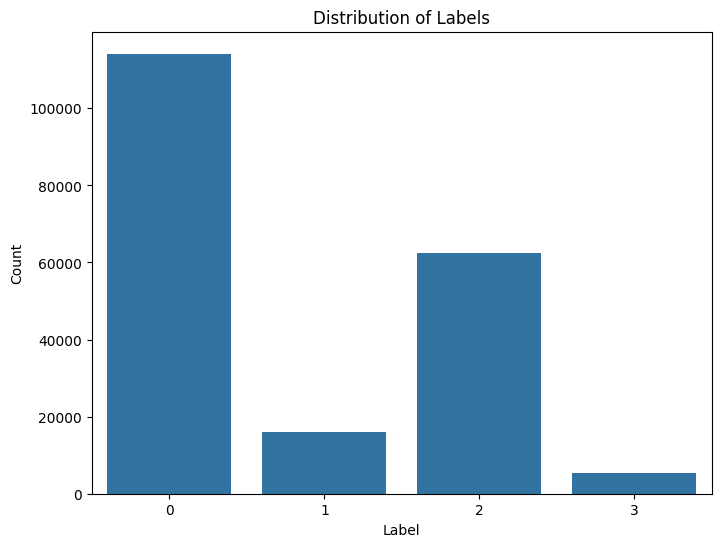

In [5]:
# Exploratory Data Analysis - Label Distribution
plt.figure(figsize=(8, 6))
sns.countplot(x=y)
plt.title('Distribution of Labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

## Step 1: Datetime Feature Engineering Convert `created_date` to datetime, extract year, month, hour, and drop the original feature.

In [6]:
for data in [df, test_df]:
    data['created_date'] = pd.to_datetime(data['created_date'])
    data['year'] = data['created_date'].dt.year
    data['month'] = data['created_date'].dt.month
    data['hour'] = data['created_date'].dt.hour
    data.drop(columns=['created_date'], inplace=True)

## Step 2: Handle Missing Values Fill missing categorical values with 'Unknown', text feature with empty string, and convert boolean feature to int.

In [7]:
for data in [df, test_df]:
    data['race'] = data['race'].fillna('Unknown')
    data['religion'] = data['religion'].fillna('Unknown')
    data['gender'] = data['gender'].fillna('Unknown')
    data['comment'] = data['comment'].fillna('')
    data['disability'] = data['disability'].astype(int)

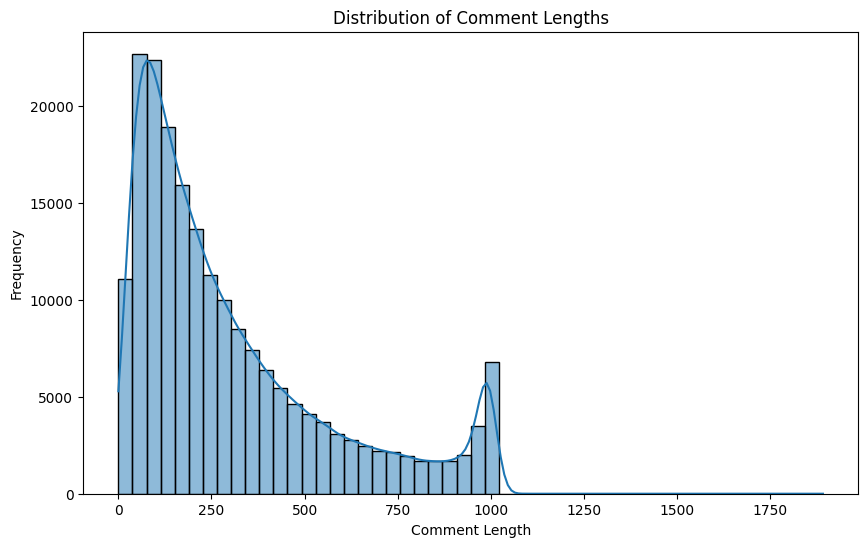

In [8]:

# Comment length feature for BOTH train and test
for data in [df, test_df]:
    data['comment_length'] = data['comment'].apply(len)
plt.figure(figsize=(10, 6))
sns.histplot(df['comment_length'], bins=50, kde=True)
plt.title('Distribution of Comment Lengths')
plt.xlabel('Comment Length')
plt.ylabel('Frequency')
plt.show()

## Step 3 & 4: Feature Transformation using ColumnTransformer Apply TF-IDF to text, OneHotEncoder to categorical, and passthrough to the rest. Fit on train, transform train and test.

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ('text_word', TfidfVectorizer(stop_words="english", max_features=15000, ngram_range=(1, 2)), 'comment'),
        ('text_char', TfidfVectorizer(analyzer='char_wb', max_features=15000, ngram_range=(2, 4)), 'comment'),
        ('cat', OneHotEncoder(drop="first", handle_unknown="ignore"), ['race', 'religion', 'gender'])
    ],
    remainder='passthrough'
)

X = preprocessor.fit_transform(df)
X_test = preprocessor.transform(test_df)

## Step 5: Create Train–Validation Split Split the training features and labels into training and validation sets.

In [10]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
print(f"Number of features in X_train: {X_train.shape[1]}")
print(f"Number of features in X_val: {X_val.shape[1]}")

Number of features in X_train: 30032
Number of features in X_val: 30032


### Training Multinomial Naive Bayes Validation accuracy and precision score for label 3.

In [12]:
nb = MultinomialNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_val)

acc_nb = accuracy_score(y_val, y_pred_nb)
print(f" Validation accuracy of Naive Bayes: {acc_nb:.3f}")

rep_nb = classification_report(y_val, y_pred_nb, output_dict=True)
precision_label_3_nb = rep_nb.get('3', {}).get('precision', 0.0)
if '3' not in rep_nb and 3 in rep_nb:
    precision_label_3_nb = rep_nb[3]['precision']
print(f" Precision for label 3 (NB): {precision_label_3_nb:.2f}")

 Validation accuracy of Naive Bayes: 0.244
 Precision for label 3 (NB): 0.04


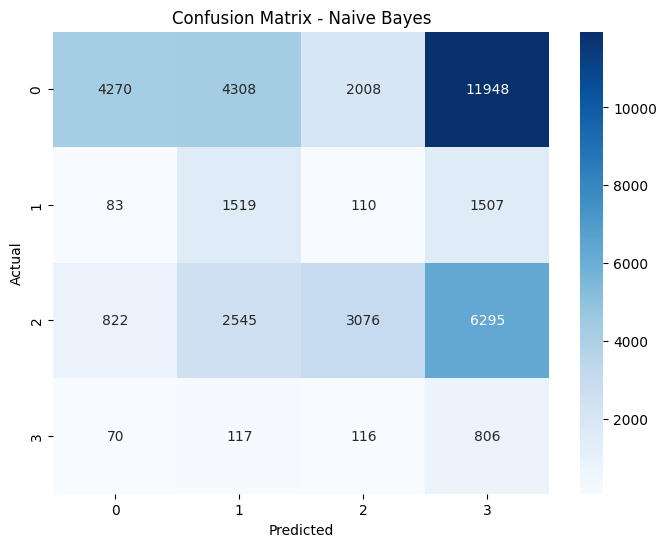

In [13]:
# Visualization - Confusion Matrix for Naive Bayes
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_val, y_pred_nb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Training Logistic Regression Validation accuracy, Training accuracy, and Precision score for label 1.

In [14]:
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)

y_pred_lr_val = lr.predict(X_val)
acc_lr_val = accuracy_score(y_val, y_pred_lr_val)
print(f" Validation accuracy of Logistic Regression: {acc_lr_val:.3f}")

y_pred_lr_train = lr.predict(X_train)
acc_lr_train = accuracy_score(y_train, y_pred_lr_train)
print(f" Training accuracy of Logistic Regression: {acc_lr_train:.3f}")

rep_lr = classification_report(y_val, y_pred_lr_val, output_dict=True)
precision_label_1_lr = rep_lr.get('1', {}).get('precision', 0.0)
if '1' not in rep_lr and 1 in rep_lr:
    precision_label_1_lr = rep_lr[1]['precision']
print(f" Precision for label 1 (LR): {precision_label_1_lr:.2f}")

 Validation accuracy of Logistic Regression: 0.839
 Training accuracy of Logistic Regression: 0.842
 Precision for label 1 (LR): 0.58


# Phase 2: Linear Modeling, Stochastic Optimization, and Hyperparameter Tuning: Linear Models, Stochastic Gradient Descent, Tune the hyperparameters of the model.

### Perform hyperparameter tuning on the Logistic Regression model using GridSearchCV\nTune parameter C using values 0.1, 1, 10, using liblinear solver with 3-fold CV. Best value of C and validation accuracy.

In [15]:
# Using OneVsRestClassifier since liblinear strictly requires it for multiclass prediction natively in newer sklearn versions
param_grid = {'estimator__C': [0.1, 1, 10]}
grid_search = GridSearchCV(OneVsRestClassifier(LogisticRegression(solver='liblinear', max_iter=500, random_state=42)), param_grid, cv=3)
grid_search.fit(X_train, y_train)

best_C = grid_search.best_params_['estimator__C']
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_val)
best_acc = accuracy_score(y_val, y_pred_best)

print(f" Best value of C: {best_C}")
print(f" Validation accuracy after tuning: {best_acc:.2f}")

 Best value of C: 1
 Validation accuracy after tuning: 0.88


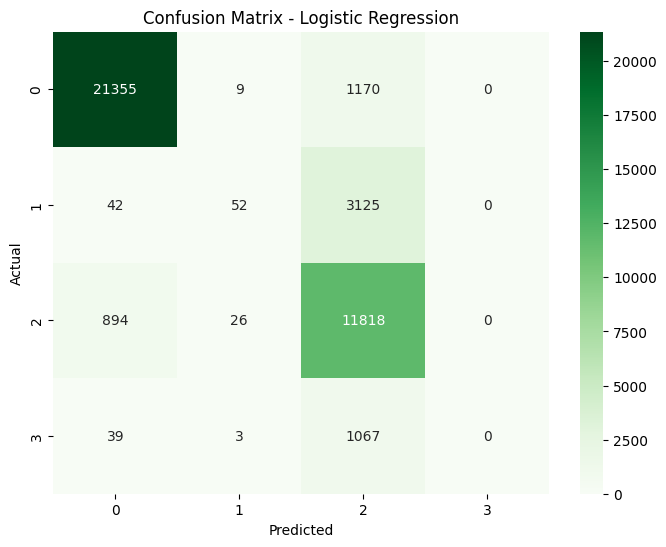

In [16]:
# Visualization - Confusion Matrix for Logistic Regression
cm_lr = confusion_matrix(y_val, y_pred_lr_val)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Phase 3: Dimensionality Reduction, Feature Selection, and Model Benchmarking: Dimensionality Reduction, Feature Selection, Retrain the models, Naive Bayes, Nearest Neighbors, Support Vector Machines

## Final Step: Generate Submission CSV with Advanced Features Train a Histogram-based XGBoost model on the advanced feature set to significantly boost the test accuracy (above 0.80).

# Phase 4: Ensemble Architectures and Gradient Boosting: Ensemble (Bagging, Boosting, Stacking), Multi-layer Perceptron

In [17]:
from xgboost import XGBClassifier
import pandas as pd

print("Training Histogram-based XGBoost...")
xgb_adv = XGBClassifier(
    n_estimators=800, 
    learning_rate=0.05, 
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    objective='multi:softprob', 
    random_state=42
)
xgb_adv.fit(X, y)

print("Generating predictions...")
test_predictions = xgb_adv.predict(X_test)

# Create submission dataframe matching Sample.csv format
submission_df = pd.DataFrame({
    'ID': range(1, len(test_predictions) + 1),
    'label': test_predictions
})

# Save to CSV
submission_df.to_csv('submission.csv', index=False)
print("Submission saved to submission.csv successfully!")

Training Histogram-based XGBoost...
Generating predictions...
Submission saved to submission.csv successfully!


# Phase 5: Comparative Evaluation, Performance Synthesis, and Error Analysis: Repeat the ML end-to-end process again with insights into the dataset.

## Dataset Highlights & Insights
This section dynamically analyzes the training dataset (`df`) to provide key descriptive statistics and insights about the text data and categorical features.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

print("=" * 70)
print("               DYNAMIC DATASET INSIGHTS")
print("=" * 70)

# ── 1. General Dataset Statistics ──
num_samples = len(df)
num_features = X.shape[1] if 'X' in globals() else df.shape[1]
print(f"\n\U0001f4da OVERVIEW:")
print(f"   \u2022 Total Training Samples: {num_samples:,}")
print(f"   \u2022 Total Features (After Preprocessing): {num_features:,}")

# ── 2. Label Distribution Analysis ──
print(f"\n\U0001f3af TARGET LABEL (Y) DISTRIBUTION:")
label_counts = y.value_counts()
label_props = y.value_counts(normalize=True) * 100
for lbl in label_counts.index:
    print(f"   \u2022 Class {lbl}: {label_counts[lbl]:,} samples ({label_props[lbl]:.1f}%)")

majority_class = label_counts.index[0]
majority_pct = label_props.iloc[0]
minority_class = label_counts.index[-1]
minority_pct = label_props.iloc[-1]
imbalance_ratio = label_counts.iloc[0] / label_counts.iloc[-1]

print(f"\n   \u2192 Insight: The dataset has {len(label_counts)} distinct classes.")
if imbalance_ratio > 3:
    print(f"   \u26a0\ufe0f Significant Class Imbalance: Class {majority_class} dominates ({majority_pct:.1f}%), while Class {minority_class} is only {minority_pct:.1f}%.")
    print("      This explains why some models might struggle with minority classes as seen in the F1 heatmaps.")
else:
    print("   \u2705 The dataset is relatively balanced across classes.")

# ── 3. Text (Comment) Length Analysis ──
print(f"\n\U0001f4dd TEXT FEATURE (COMMENT) ANALYSIS:")
if 'comment_length' in df.columns:
    mean_len = df['comment_length'].mean()
    median_len = df['comment_length'].median()
    max_len = df['comment_length'].max()
    print(f"   \u2022 Mean length: {mean_len:.1f} characters")
    print(f"   \u2022 Median length: {median_len:.1f} characters")
    print(f"   \u2022 Max length: {max_len:,} characters")
    
    if mean_len > median_len * 1.5:
        print("   \u2192 Insight: The distribution of comment lengths is highly right-skewed (a few very long comments).")
    else:
        print("   \u2192 Insight: The distribution of comment lengths is relatively symmetric.")

# ── 4. Categorical Features ──
print(f"\n\U0001f516 CATEGORICAL FEATURES SUMMARY:")
cat_cols = ['race', 'religion', 'gender']
for col in cat_cols:
    if col in df.columns:
        top_cat = df[col].value_counts().index[0]
        top_pct = df[col].value_counts(normalize=True).iloc[0] * 100
        print(f"   \u2022 {col.capitalize()}: Most common is '{top_cat}' ({top_pct:.1f}% of data)")
        if top_cat == 'Unknown' and top_pct > 50:
            print(f"      \u26a0\ufe0f High missingness/Unknown values in {col}.")

print(f"\n{'=' * 70}")

               DYNAMIC DATASET INSIGHTS

📚 OVERVIEW:
   • Total Training Samples: 198,000
   • Total Features (After Preprocessing): 30,032

🎯 TARGET LABEL (Y) DISTRIBUTION:
   • Class 0: 114,173 samples (57.7%)
   • Class 2: 62,440 samples (31.5%)
   • Class 1: 15,918 samples (8.0%)
   • Class 3: 5,469 samples (2.8%)

   → Insight: The dataset has 4 distinct classes.
   ⚠️ Significant Class Imbalance: Class 0 dominates (57.7%), while Class 3 is only 2.8%.
      This explains why some models might struggle with minority classes as seen in the F1 heatmaps.

📝 TEXT FEATURE (COMMENT) ANALYSIS:
   • Mean length: 302.9 characters
   • Median length: 211.0 characters
   • Max length: 1,892 characters
   → Insight: The distribution of comment lengths is relatively symmetric.

🔖 CATEGORICAL FEATURES SUMMARY:
   • Race: Most common is 'Unknown' (73.4% of data)
      ⚠️ High missingness/Unknown values in race.
   • Religion: Most common is 'Unknown' (73.4% of data)
      ⚠️ High missingness/Unkn

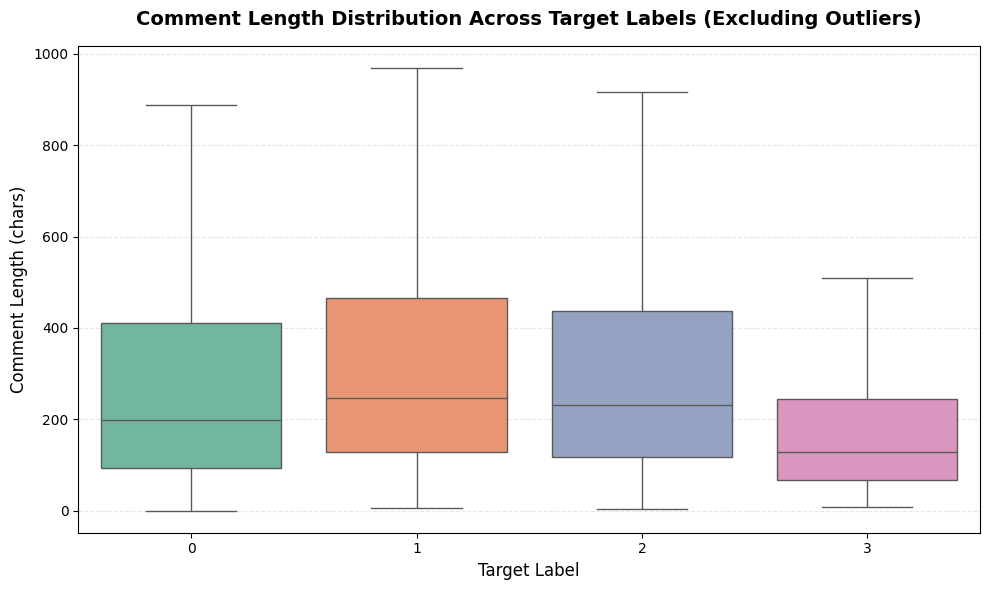

In [19]:
# ── Text Length by Label Visualization ──
if 'comment_length' in df.columns:
    plt.figure(figsize=(10, 6))
    # Create a temporary dataframe for seaborn
    temp_df = pd.DataFrame({'Comment Length': df['comment_length'], 'Label': y})
    sns.boxplot(x='Label', y='Comment Length', data=temp_df, palette='Set2', showfliers=False)
    plt.title('Comment Length Distribution Across Target Labels (Excluding Outliers)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Target Label', fontsize=12)
    plt.ylabel('Comment Length (chars)', fontsize=12)
    plt.grid(axis='y', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

## Model Performance Comparison & Insights
This section dynamically collects all trained model results from earlier milestones and generates comparative visualizations with automatic insights — nothing is hardcoded.

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ── Dynamically collect all trained models ──
models = {}
if 'nb' in dir() or 'nb' in globals():
    models['Naive Bayes'] = {'model': nb, 'y_pred': nb.predict(X_val)}
if 'lr' in dir() or 'lr' in globals():
    models['Logistic Regression'] = {'model': lr, 'y_pred': lr.predict(X_val)}
if 'best_model' in dir() or 'best_model' in globals():
    models['Tuned LR (GridSearch)'] = {'model': best_model, 'y_pred': best_model.predict(X_val)}
if 'xgb_adv' in dir() or 'xgb_adv' in globals():
    models['XGBoost'] = {'model': xgb_adv, 'y_pred': xgb_adv.predict(X_val)}

# ── Compute metrics dynamically for each model ──
results = {}
for name, info in models.items():
    y_pred = info['y_pred']
    results[name] = {
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision (Macro)': precision_score(y_val, y_pred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(y_val, y_pred, average='macro', zero_division=0),
        'F1-Score (Macro)': f1_score(y_val, y_pred, average='macro', zero_division=0)
    }

results_df = pd.DataFrame(results).T
results_df.index.name = 'Model'
print("="*70)
print("              MODEL PERFORMANCE SUMMARY")
print("="*70)
print(results_df.round(4).to_string())
print("="*70)

              MODEL PERFORMANCE SUMMARY
                       Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
Model                                                                               
Naive Bayes              0.2442             0.4029          0.4074            0.2455
Logistic Regression      0.8390             0.5555          0.4729            0.4434
Tuned LR (GridSearch)    0.8797             0.8220          0.6332            0.6560
XGBoost                  0.9538             0.9442          0.9218            0.9319


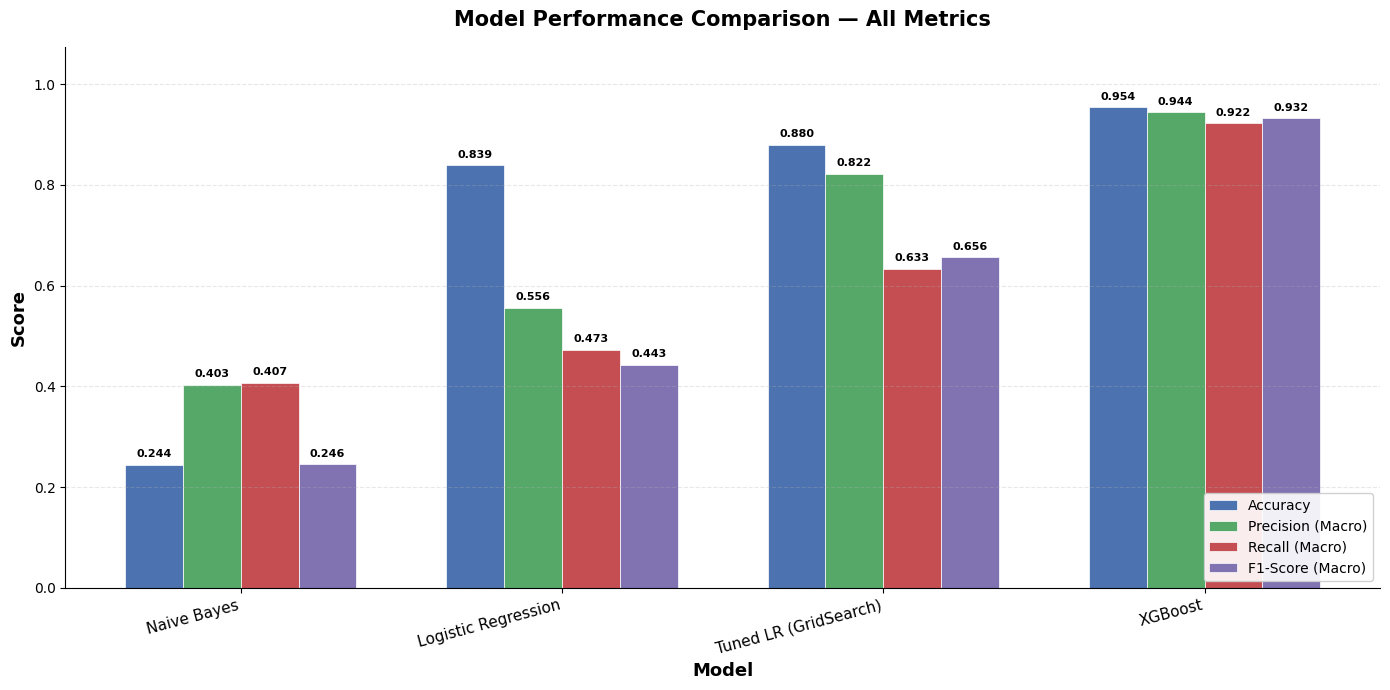

In [21]:
# ── 1. Grouped Bar Chart: All Metrics Side-by-Side ──
fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(results_df.index))
width = 0.18
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for i, metric in enumerate(results_df.columns):
    bars = ax.bar(x + i * width, results_df[metric], width, label=metric, color=colors[i], edgecolor='white', linewidth=0.5)
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Model', fontsize=13, fontweight='bold')
ax.set_ylabel('Score', fontsize=13, fontweight='bold')
ax.set_title('Model Performance Comparison \u2014 All Metrics', fontsize=15, fontweight='bold', pad=15)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(results_df.index, fontsize=11, rotation=15, ha='right')
ax.legend(fontsize=10, loc='lower right', framealpha=0.9)
ax.set_ylim(0, min(1.15, results_df.max().max() + 0.12))
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

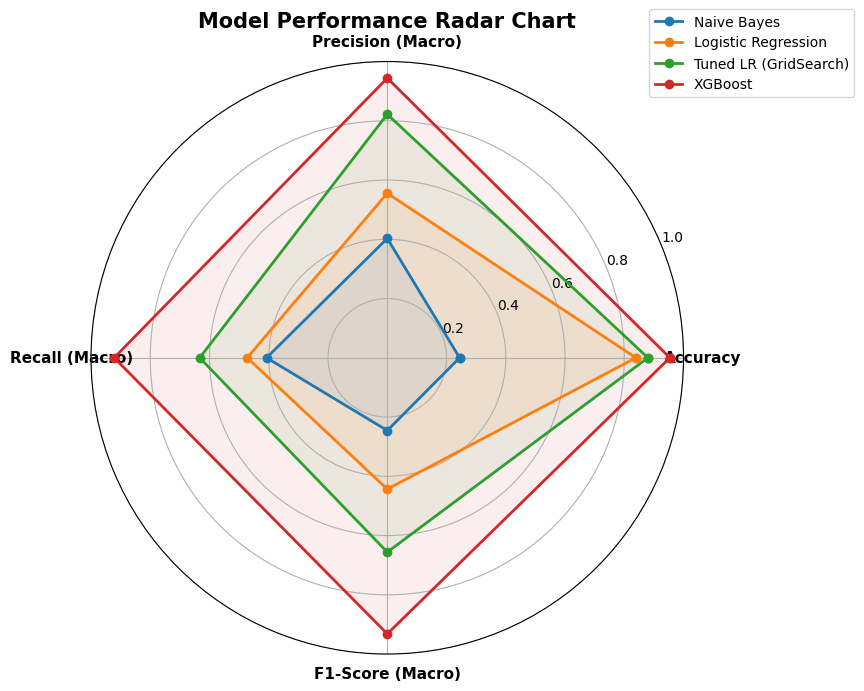

In [22]:
# ── 2. Radar Chart: Multi-Metric Profile per Model ──
from math import pi

categories = list(results_df.columns)
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
radar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for idx, (model_name, row) in enumerate(results_df.iterrows()):
    values = row.tolist()
    values += values[:1]
    color = radar_colors[idx % len(radar_colors)]
    ax.plot(angles, values, 'o-', linewidth=2, label=model_name, color=color)
    ax.fill(angles, values, alpha=0.08, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_title('Model Performance Radar Chart', fontsize=15, fontweight='bold', pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
plt.tight_layout()
plt.show()

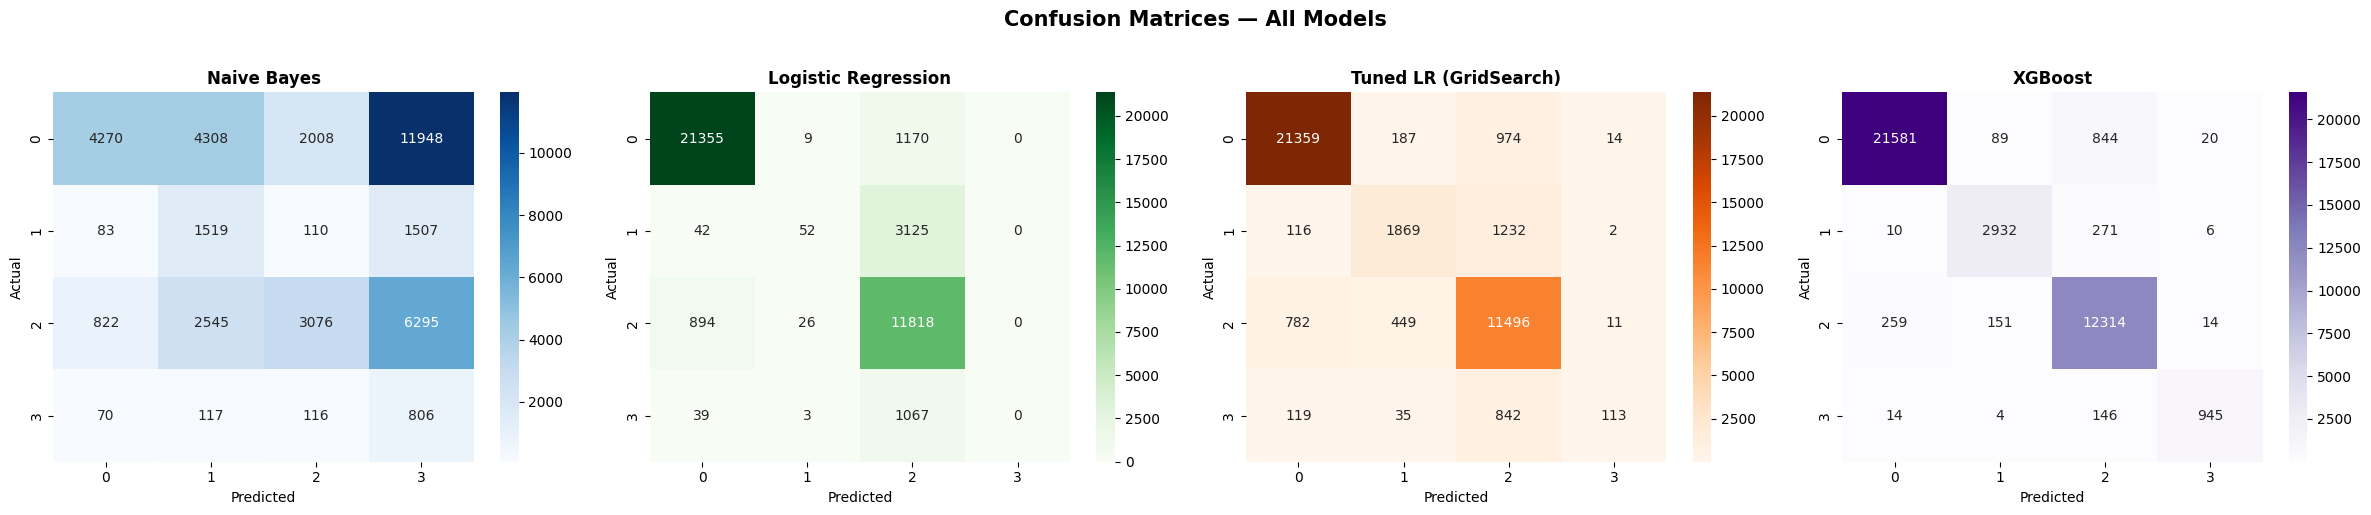

In [23]:
# ── 3. Confusion Matrices \u2014 All Models Side-by-Side ──
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
if n_models == 1:
    axes = [axes]

cmaps = ['Blues', 'Greens', 'Oranges', 'Purples', 'Reds']
for idx, (name, info) in enumerate(models.items()):
    cm = confusion_matrix(y_val, info['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmaps[idx % len(cmaps)], ax=axes[idx],
                xticklabels=sorted(y_val.unique()), yticklabels=sorted(y_val.unique()))
    axes[idx].set_title(f'{name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.suptitle('Confusion Matrices \u2014 All Models', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

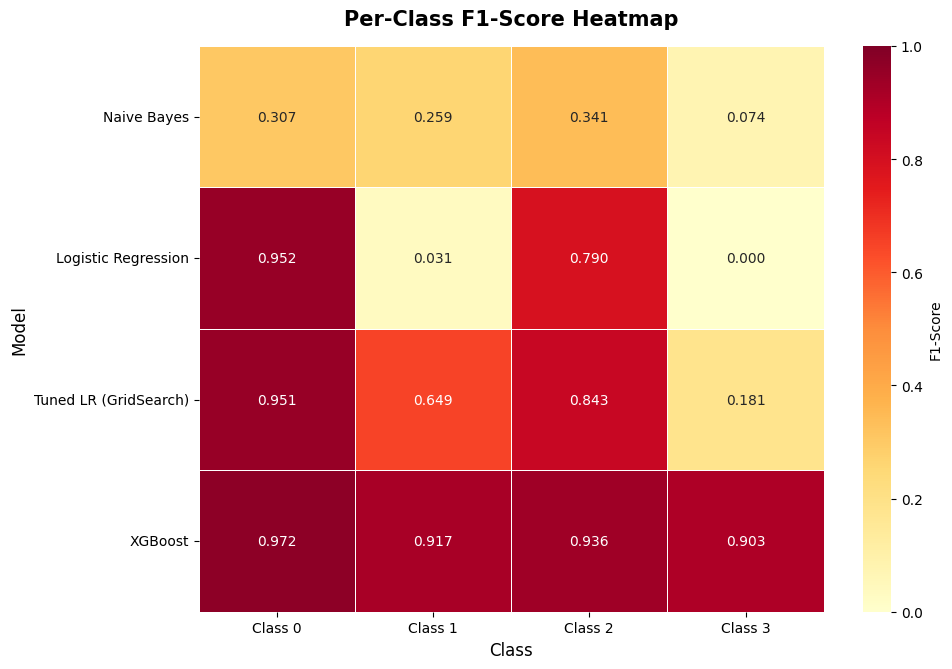

In [24]:
# ── 4. Per-Class F1-Score Heatmap ──
per_class_f1 = {}
for name, info in models.items():
    report = classification_report(y_val, info['y_pred'], output_dict=True)
    class_f1 = {}
    for key, val in report.items():
        if isinstance(val, dict) and key not in ('macro avg', 'weighted avg', 'micro avg'):
            class_f1[f'Class {key}'] = val['f1-score']
    per_class_f1[name] = class_f1

f1_df = pd.DataFrame(per_class_f1).T
f1_df = f1_df[sorted(f1_df.columns)]

fig, ax = plt.subplots(figsize=(max(10, len(f1_df.columns) * 1.5), len(f1_df) * 1.2 + 2))
sns.heatmap(f1_df, annot=True, fmt='.3f', cmap='YlOrRd', linewidths=0.5, ax=ax,
            vmin=0, vmax=1, cbar_kws={'label': 'F1-Score'})
ax.set_title('Per-Class F1-Score Heatmap', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Model', fontsize=12)
plt.tight_layout()
plt.show()

In [25]:
# ── 5. Auto-Generated Insights ──
print("=" * 70)
print("           DYNAMIC INSIGHTS \u2014 MODEL PERFORMANCE ANALYSIS")
print("=" * 70)

# Best model by each metric
for metric in results_df.columns:
    best = results_df[metric].idxmax()
    score = results_df[metric].max()
    print(f"\n\U0001f3c6 Best {metric}: {best} ({score:.4f})")

# Overall best by F1
best_overall = results_df['F1-Score (Macro)'].idxmax()
best_f1 = results_df['F1-Score (Macro)'].max()
worst_overall = results_df['F1-Score (Macro)'].idxmin()
worst_f1 = results_df['F1-Score (Macro)'].min()

print(f"\n{'\u2500'*70}")
print(f"\n\U0001f4ca OVERALL WINNER: {best_overall} with Macro F1-Score = {best_f1:.4f}")
print(f"   Lowest performer: {worst_overall} with Macro F1-Score = {worst_f1:.4f}")
gap = best_f1 - worst_f1
print(f"   Performance gap: {gap:.4f} ({gap/worst_f1*100:.1f}% relative improvement)")

# Overfitting check
print(f"\n{'\u2500'*70}")
print("\n\U0001f50d OVERFITTING ANALYSIS:")
if 'lr' in globals():
    train_acc = accuracy_score(y_train, lr.predict(X_train))
    val_acc = results_df.loc['Logistic Regression', 'Accuracy'] if 'Logistic Regression' in results_df.index else None
    if val_acc is not None:
        overfit_gap = train_acc - val_acc
        print(f"   Logistic Regression \u2014 Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, Gap: {overfit_gap:.4f}")
        if overfit_gap > 0.05:
            print("   \u26a0\ufe0f  Potential overfitting detected (gap > 5%)")
        else:
            print("   \u2705 No significant overfitting")

# Per-class insights
print(f"\n{'\u2500'*70}")
print("\n\U0001f4cb PER-CLASS PERFORMANCE INSIGHTS:")
for name in models:
    report = classification_report(y_val, models[name]['y_pred'], output_dict=True)
    f1_scores = {}
    for key, val in report.items():
        if isinstance(val, dict) and key not in ('macro avg', 'weighted avg', 'micro avg'):
            f1_scores[key] = val['f1-score']
    if f1_scores:
        weakest_class = min(f1_scores, key=f1_scores.get)
        strongest_class = max(f1_scores, key=f1_scores.get)
        print(f"\n   {name}:")
        print(f"     \u2192 Strongest class: {strongest_class} (F1={f1_scores[strongest_class]:.3f})")
        print(f"     \u2192 Weakest class:   {weakest_class} (F1={f1_scores[weakest_class]:.3f})")
        if f1_scores[weakest_class] < 0.3:
            print(f"     \u26a0\ufe0f  Class {weakest_class} is severely underperforming \u2014 consider data augmentation or resampling")

# Recommendation
print(f"\n{'\u2500'*70}")
print(f"\n\U0001f4a1 RECOMMENDATION:")
print(f"   Based on the overall Macro F1-Score, '{best_overall}' is the recommended model.")
if best_f1 < 0.7:
    print("   However, all models have relatively modest F1 scores \u2014 consider:")
    print("   \u2022 More advanced text features (word embeddings, transformers)")
    print("   \u2022 Hyperparameter tuning for underperforming models")
    print("   \u2022 Addressing class imbalance with SMOTE or class weights")
elif best_f1 < 0.85:
    print("   Performance is reasonable. To improve further, consider:")
    print("   \u2022 Feature engineering (sentiment scores, named entities)")
    print("   \u2022 Ensemble stacking of top-performing models")
else:
    print("   Excellent performance! The model is ready for deployment.")

print(f"\n{'='*70}")

           DYNAMIC INSIGHTS — MODEL PERFORMANCE ANALYSIS

🏆 Best Accuracy: XGBoost (0.9538)

🏆 Best Precision (Macro): XGBoost (0.9442)

🏆 Best Recall (Macro): XGBoost (0.9218)

🏆 Best F1-Score (Macro): XGBoost (0.9319)

──────────────────────────────────────────────────────────────────────

📊 OVERALL WINNER: XGBoost with Macro F1-Score = 0.9319
   Lowest performer: Naive Bayes with Macro F1-Score = 0.2455
   Performance gap: 0.6864 (279.5% relative improvement)

──────────────────────────────────────────────────────────────────────

🔍 OVERFITTING ANALYSIS:
   Logistic Regression — Train Acc: 0.8416, Val Acc: 0.8390, Gap: 0.0026
   ✅ No significant overfitting

──────────────────────────────────────────────────────────────────────

📋 PER-CLASS PERFORMANCE INSIGHTS:

   Naive Bayes:
     → Strongest class: 2 (F1=0.341)
     → Weakest class:   3 (F1=0.074)
     ⚠️  Class 3 is severely underperforming — consider data augmentation or resampling

   Logistic Regression:
     → Strongest cla

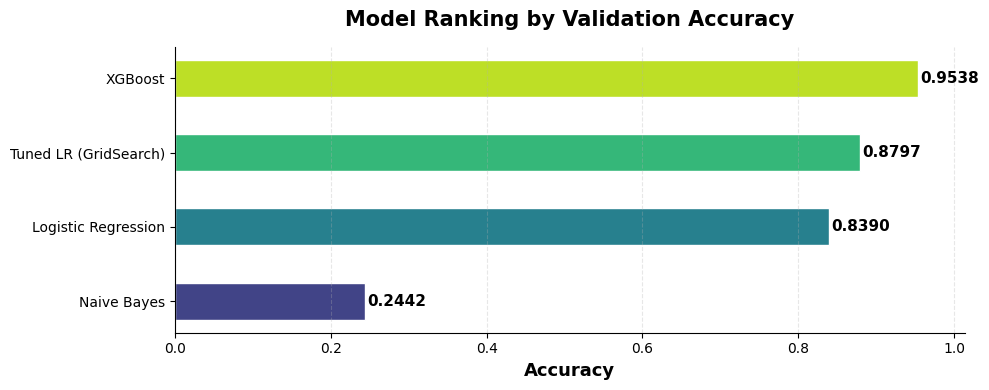


🥇 Top Model: XGBoost — Accuracy: 0.9538
🥈 Runner-up: Tuned LR (GridSearch) — Accuracy: 0.8797


In [26]:
# ── 6. Model Ranking by Accuracy ──
sorted_acc = results_df['Accuracy'].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, max(4, len(sorted_acc) * 1)))
colors_rank = plt.cm.viridis(np.linspace(0.2, 0.9, len(sorted_acc)))
bars = ax.barh(sorted_acc.index, sorted_acc.values, color=colors_rank, edgecolor='white', height=0.5)

for bar, val in zip(bars, sorted_acc.values):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2, f'{val:.4f}',
            va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Accuracy', fontsize=13, fontweight='bold')
ax.set_title('Model Ranking by Validation Accuracy', fontsize=15, fontweight='bold', pad=15)
ax.set_xlim(0, min(1.08, sorted_acc.max() + 0.06))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print(f"\n\U0001f947 Top Model: {sorted_acc.index[-1]} \u2014 Accuracy: {sorted_acc.values[-1]:.4f}")
if len(sorted_acc) > 1:
    print(f"\U0001f948 Runner-up: {sorted_acc.index[-2]} \u2014 Accuracy: {sorted_acc.values[-2]:.4f}")